# Praxis Pipeline Steps 1 & 2 — Dataset Selection and Preprocessing
**GWU Praxis, Chapter 3 (Sections 3.3–3.4)**

Loads CIC-IDS2017, UNSW-NB15 and NSL-KDD, removes the held-out (zero-day) class, removes exact duplicate records, splits the remaining records 70/15/15, and then cleans, encodes, selects and scales features using statistics from the **training split only**.

**Held-out classes:** Web Attack – SQL Injection (CIC-IDS2017), Shellcode (UNSW-NB15), and the four KDDTrain+ U2R subtypes buffer_overflow, loadmodule, perl and rootkit (NSL-KDD) — the classes the praxis reports.

**Produces** (in `outputs_praxis_heldout/pipeline/`): `*_train.csv`, `*_val.csv`, `*_test_standard.csv`, `*_test_zeroday.csv`, `*_preprocess.pkl`, `*_scaler.pkl`, `dedup_log.csv`, `class_counts.csv`.

Run the cells in order. Nothing in this notebook trains a model.

## 0 · Install and imports

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# INSTALL
# Colab already has pandas, NumPy and scikit-learn; this only fills gaps.
# ────────────────────────────────────────────────────────────────────────────
!pip install -q pandas numpy scikit-learn matplotlib

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# IMPORTS AND RANDOM SEED
# One seed (42) is set for Python, NumPy and TensorFlow so every split and
# sample in this notebook is reproducible.
# ────────────────────────────────────────────────────────────────────────────
import os, pickle, random, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("ready")

ready


## 1 · Configuration

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# SESSION SETUP AND SETTINGS
#
# Mounts Google Drive and fixes the settings every later step relies on:
# dataset files, label column, held-out class, categorical columns, and the
# feature-screening thresholds from Section 3.4.1.
# PRAXIS_BASE (environment variable) lets the notebook run outside Colab.
# ────────────────────────────────────────────────────────────────────────────
# Set this to your project folder in Google Drive (it must end with "/").
BASE = os.environ.get("PRAXIS_BASE", "/content/drive/MyDrive/<YOUR_PROJECT_FOLDER>/")
RUN_DIR = "outputs_praxis_heldout"   # results folder
if "PRAXIS_BASE" not in os.environ:
    from google.colab import drive
    drive.mount("/content/drive")

OUT = Path(BASE) / RUN_DIR / "pipeline"
(OUT / "figures").mkdir(parents=True, exist_ok=True)

DATASETS = ["CIC-IDS2017", "UNSW-NB15", "NSL-KDD"]

DATA_PATHS = {
    "CIC-IDS2017": [f"{BASE}datasets/CIC-IDS2017/{f}" for f in [
        "Monday-WorkingHours.pcap_ISCX.csv",
        "Tuesday-WorkingHours.pcap_ISCX.csv",
        "Wednesday-workingHours.pcap_ISCX.csv",
        "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
        "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
        "Friday-WorkingHours-Morning.pcap_ISCX.csv",
        "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
        "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]],
    "UNSW-NB15": [f"{BASE}datasets/UNSW-NB15/UNSW_NB15_training-set.csv",
                  f"{BASE}datasets/UNSW-NB15/UNSW_NB15_testing-set.csv"],
    "NSL-KDD":   [f"{BASE}datasets/NSL-KDD/KDDTrain+.txt",
                  f"{BASE}datasets/NSL-KDD/KDDTest+.txt"],
}

LABEL_COL = {"CIC-IDS2017": "Label", "UNSW-NB15": "attack_cat", "NSL-KDD": "class"}

# Held-out (zero-day proxy) labels. A label matches when it equals one of these
# after lower-casing and removing every character that is not a letter or digit.
# This handles the mis-encoded dash in CIC-IDS2017's "Web Attack – ..." labels
# without substring matching, so no other label is removed by accident.
HOLDOUT = {"CIC-IDS2017": ["Web Attack - Sql Injection"],
           "UNSW-NB15":   ["Shellcode"],
           "NSL-KDD":     ["buffer_overflow", "loadmodule", "perl", "rootkit"]}   # the four KDDTrain+ U2R subtypes

def norm_label(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def holdout_mask(labels, name):
    wanted = {norm_label(h) for h in HOLDOUT[name]}
    return labels.astype(str).map(norm_label).isin(wanted).to_numpy()

# Text columns that are one-hot encoded (Section 3.4.3).
CAT_COLS  = {"CIC-IDS2017": [], "UNSW-NB15": ["proto", "service", "state"],
             "NSL-KDD": ["protocol_type", "service", "flag"]}
DROP_COLS = {"CIC-IDS2017": [], "UNSW-NB15": ["id", "label"], "NSL-KDD": ["difficulty"]}

NSL_COLS = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "class","difficulty"]

DEDUPLICATE   = True     # drop exact duplicate records before splitting, and again on the final model input
VAR_THRESH    = 0.001    # Section 3.4.1: drop features with training variance below this
CORR_THRESH   = 0.95     # Section 3.4.1: drop the lower-variance feature of each pair above this
CORR_SAMPLE   = 200_000  # training rows used to estimate correlations
MIN_CLASS_ROWS = 3       # a class needs at least 3 records: one each for train, val and test

Mounted at /content/drive


---
## Step 1 · Load datasets

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# LOAD RAW FILES
#
# Reads every file for each dataset, strips stray spaces from column names and
# labels, and reports class counts. encoding_errors="replace" handles the
# non-UTF-8 dash in CIC-IDS2017's "Web Attack – ..." labels.
# The UNSW-NB15 files start with a byte-order mark (BOM), which can turn the
# first column name "id" into "ï»¿id". The BOM is removed from the column names
# so the row identifier is dropped, and the notebook stops if a column named id
# survives.
# ────────────────────────────────────────────────────────────────────────────
def load(name):
    frames = []
    for p in DATA_PATHS[name]:
        if name == "NSL-KDD":
            df = pd.read_csv(p, header=None, names=NSL_COLS)
        else:
            df = pd.read_csv(p, low_memory=False, encoding_errors="replace")
        df.columns = df.columns.str.replace("\ufeff", "", regex=False).str.replace("ï»¿", "", regex=False).str.strip()
        frames.append(df)
    df = pd.concat(frames, ignore_index=True)
    df[LABEL_COL[name]] = df[LABEL_COL[name]].astype(str).str.strip()
    df = df.drop(columns=DROP_COLS[name], errors="ignore")
    assert "id" not in df.columns, f"{name}: row identifier 'id' is still a column"
    return df

raw = {name: load(name) for name in DATASETS}

for name, df in raw.items():
    lab = LABEL_COL[name]
    n_hold = holdout_mask(df[lab], name).sum()
    print(f"{name}: {len(df):,} rows, {df.shape[1]-1} columns, {df[lab].nunique()} classes; "
          f"held-out {sorted(df.loc[holdout_mask(df[lab], name), lab].unique())}: {n_hold:,} rows")
    assert n_hold > 0, f"{name}: held-out label not found — check HOLDOUT spelling"

CIC-IDS2017: 2,830,743 rows, 78 columns, 15 classes; held-out ['Web Attack � Sql Injection']: 21 rows
UNSW-NB15: 257,673 rows, 42 columns, 10 classes; held-out ['Shellcode']: 1,511 rows
NSL-KDD: 148,517 rows, 41 columns, 40 classes; held-out ['buffer_overflow', 'loadmodule', 'perl', 'rootkit']: 89 rows


## Step 2.1 · Exploratory look at class balance
Class-distribution plots only. Feature screening (low variance, high correlation) is done later on the **training split**, so the test data never influences which features are kept.

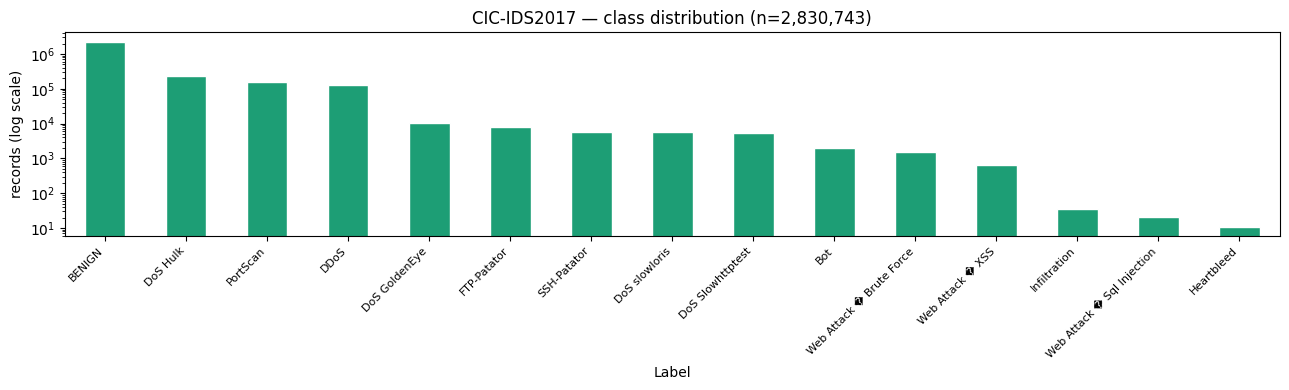

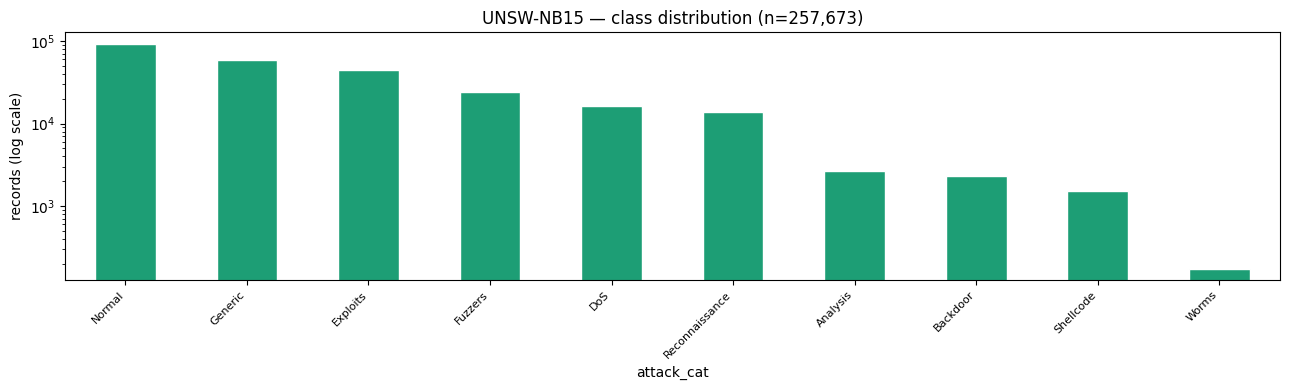

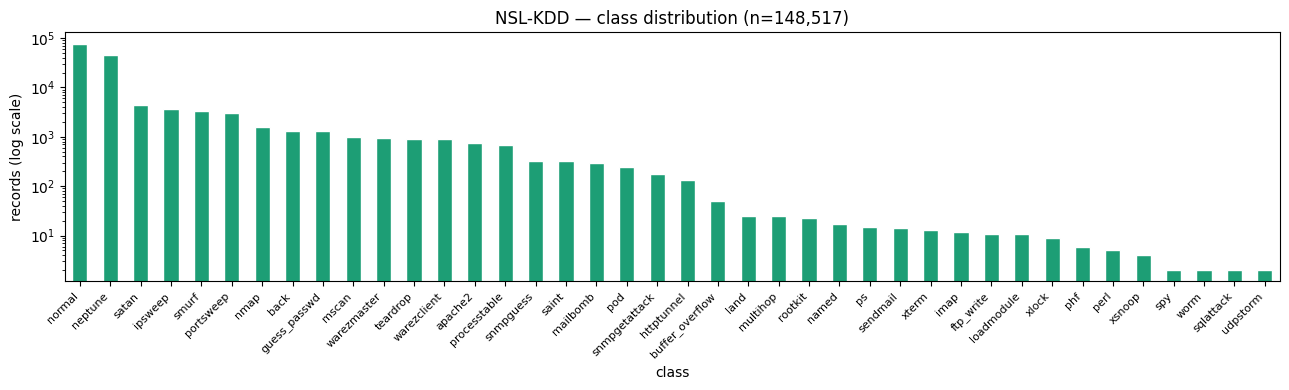

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# CLASS DISTRIBUTION PLOTS
# One bar chart per dataset (log scale, because the largest classes are
# thousands of times bigger than the smallest). Saved to outputs_praxis_heldout/pipeline/figures.
# ────────────────────────────────────────────────────────────────────────────
for name, df in raw.items():
    counts = df[LABEL_COL[name]].value_counts()
    fig, ax = plt.subplots(figsize=(13, 4))
    counts.plot(kind="bar", ax=ax, color="#1D9E75", edgecolor="white", logy=True)
    ax.set_title(f"{name} — class distribution (n={len(df):,})")
    ax.set_ylabel("records (log scale)")
    plt.xticks(rotation=45, ha="right", fontsize=8)
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"{name}_class_distribution.png", dpi=150)
    plt.show()

## Step 2.2 · Preprocessing functions
Each function is **fitted on the training split only** and then applied unchanged to validation, test and held-out records (Sections 3.4.2–3.4.4).

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# CLEANING: infinite and missing values (Section 3.4.2)
#
# fit_cleaner learns, from training rows only, each numeric feature's 99th
# percentile (of finite values) and median. apply_cleaner replaces ±inf with the
# 99th percentile and NaN with the median. A per-class percentile is not used
# because the class of a test record is unknown at prediction time.
# ────────────────────────────────────────────────────────────────────────────
def fit_cleaner(train, num_cols):
    finite = train[num_cols].replace([np.inf, -np.inf], np.nan)
    return {"p99": finite.quantile(0.99), "median": finite.median().fillna(0.0)}

def apply_cleaner(df, num_cols, stats):
    df = df.copy()
    vals = df[num_cols].astype("float64")
    vals = vals.mask(np.isposinf(vals), stats["p99"], axis=1)
    vals = vals.mask(np.isneginf(vals), -stats["p99"].abs(), axis=1)
    df[num_cols] = vals.fillna(stats["median"])
    return df

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# ONE-HOT ENCODING OF TEXT COLUMNS (Section 3.4.3)
#
# Fitted on training rows; a category that first appears in test data becomes
# all zeros (handle_unknown="ignore") rather than an error.
# ────────────────────────────────────────────────────────────────────────────
def fit_onehot(train, cat_cols):
    if not cat_cols:
        return None
    ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore", dtype=np.float32)
    ohe.fit(train[cat_cols].astype(str))
    return ohe

def apply_onehot(df, cat_cols, ohe):
    if ohe is None:
        return df
    enc = pd.DataFrame(ohe.transform(df[cat_cols].astype(str)),
                       columns=ohe.get_feature_names_out(cat_cols), index=df.index)
    return pd.concat([df.drop(columns=cat_cols), enc], axis=1)

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# FEATURE SCREENING (Section 3.4.1), training rows only
#
# 1. Drop features whose training variance is below VAR_THRESH.
# 2. For every pair with |Pearson r| > CORR_THRESH, drop the member with the
#    lower variance. Pairs are processed from the most to the least correlated
#    so each decision uses only features still in the set.
# ────────────────────────────────────────────────────────────────────────────
def select_features(train, feat_cols):
    var = train[feat_cols].var()
    low_var = var[var < VAR_THRESH].index.tolist()
    keep = [c for c in feat_cols if c not in low_var]

    sample = train[keep].sample(n=min(CORR_SAMPLE, len(train)), random_state=RANDOM_SEED)
    corr = sample.corr().abs()
    iu = np.triu_indices_from(corr, k=1)
    pairs = sorted(((corr.values[i, j], corr.index[i], corr.columns[j])
                    for i, j in zip(*iu) if np.isfinite(corr.values[i, j]) and corr.values[i, j] > CORR_THRESH),
                   reverse=True)
    dropped_corr = []
    for r, a, b in pairs:
        if a in dropped_corr or b in dropped_corr:
            continue
        loser = a if var[a] < var[b] else b
        dropped_corr.append(loser)
    keep = [c for c in keep if c not in dropped_corr]
    return keep, low_var, dropped_corr

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# STRATIFIED 70 / 15 / 15 SPLIT (Section 3.4.5)
#
# Splits every class separately, so each class keeps its share in all three
# splits. scikit-learn's two-stage train_test_split fails when a rare class
# leaves only one record for the second stage; this version instead gives
# every class with at least MIN_CLASS_ROWS records at least one record in
# validation and in test, and the rest (about 70%) to training.
# ────────────────────────────────────────────────────────────────────────────
def stratified_three_way(df, lab, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    idx = {"train": [], "val": [], "test": []}
    for cls, rows in df.groupby(lab).indices.items():
        rows = rng.permutation(rows)
        n = len(rows)
        n_val = max(1, int(round(0.15 * n)))
        n_test = max(1, int(round(0.15 * n)))
        idx["val"].append(rows[:n_val])
        idx["test"].append(rows[n_val:n_val + n_test])
        idx["train"].append(rows[n_val + n_test:])
    return tuple(df.iloc[rng.permutation(np.concatenate(idx[k]))].reset_index(drop=True)
                 for k in ["train", "val", "test"])

## Step 2.3 · Held-out isolation, de-duplication and split
Order of operations (Section 3.4.5): the held-out class is removed first, then exact duplicates are removed, then the remaining records are split 70 / 15 / 15 with stratification. All fitting happens after the split, on training rows only.

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# RUN PREPROCESSING FOR EACH DATASET
#
# For each dataset:
#   a. separate the held-out class into the zero-day set;
#   b. drop exact duplicate records (same features and label) among the known
#      records, and drop held-out records that duplicate a known record's
#      features (they are not unseen traffic);
#   c. stratified 70 / 15 / 15 split of the known records;
#   d. fit cleaning, one-hot, feature screening and Min-Max scaling on the
#      training split and apply them to every split, including the zero-day set;
#   e. de-duplicate again on the final model input. Step b compares raw
#      records; once columns are dropped and values scaled, some records that
#      differed only in a dropped column become identical. A validation
#      record identical to a training record, a test record identical to a
#      training or validation record, and a held-out record identical to any
#      known record are removed and counted.
# Held-out records are treated exactly like standard test records (no clipping
# to the training range), so both test sets are processed identically.
# ────────────────────────────────────────────────────────────────────────────
dedup_rows, count_rows, processed = [], [], {}

for name in DATASETS:
    lab, cats = LABEL_COL[name], CAT_COLS[name]
    df = raw[name]
    print(f"\n── {name} ──")

    # a. held-out isolation
    hold_mask = holdout_mask(df[lab], name)
    holdout_labels = sorted(df.loc[hold_mask, lab].unique().tolist())
    zeroday, known = df[hold_mask].copy(), df[~hold_mask].copy()
    feature_cols_raw = [c for c in df.columns if c != lab]

    # b. de-duplication
    n_known0, n_zd0 = len(known), len(zeroday)
    if DEDUPLICATE:
        known = known.drop_duplicates()
        zeroday = zeroday.drop_duplicates()
        known_keys = set(pd.util.hash_pandas_object(known[feature_cols_raw], index=False))
        zd_keys = pd.util.hash_pandas_object(zeroday[feature_cols_raw], index=False).to_numpy()
        zeroday = zeroday[~np.isin(zd_keys, list(known_keys))]
    conflicts = int(known.duplicated(subset=feature_cols_raw, keep=False).sum())
    dedup_rows.append(dict(dataset=name, known_before=n_known0, known_after=len(known),
                           heldout_before=n_zd0, heldout_after=len(zeroday),
                           known_rows_with_conflicting_labels=conflicts))
    print(f"  duplicates removed: known {n_known0-len(known):,}, held-out {n_zd0-len(zeroday):,}; "
          f"records sharing features but not label: {conflicts:,}")

    # c. stratified split (classes too small for a three-way split are dropped and logged)
    vc = known[lab].value_counts()
    too_small = vc[vc < MIN_CLASS_ROWS].index.tolist()
    if too_small:
        print(f"  classes with < {MIN_CLASS_ROWS} records dropped: {too_small}")
    known = known[~known[lab].isin(too_small)].reset_index(drop=True)
    train, val, test = stratified_three_way(known, lab)
    parts = {"train": train, "val": val, "test_standard": test, "test_zeroday": zeroday}

    # d. fit on train, apply everywhere
    num_cols = [c for c in feature_cols_raw if c not in cats]
    for k in parts:                                    # coerce stray text in numeric columns
        parts[k][num_cols] = parts[k][num_cols].apply(pd.to_numeric, errors="coerce")
    clean_stats = fit_cleaner(parts["train"], num_cols)
    parts = {k: apply_cleaner(v, num_cols, clean_stats) for k, v in parts.items()}
    ohe = fit_onehot(parts["train"], cats)
    parts = {k: apply_onehot(v, cats, ohe) for k, v in parts.items()}

    all_feats = [c for c in parts["train"].columns if c != lab]
    feat_cols, low_var, corr_drop = select_features(parts["train"], all_feats)
    print(f"  features: {len(all_feats)} after encoding → {len(feat_cols)} kept "
          f"({len(low_var)} low-variance, {len(corr_drop)} highly correlated dropped)")

    scaler = MinMaxScaler().fit(parts["train"][feat_cols])
    for k in parts:
        scaled = pd.DataFrame(scaler.transform(parts[k][feat_cols]).astype(np.float32),
                              columns=feat_cols, index=parts[k].index)
        parts[k] = pd.concat([scaled, parts[k][[lab]]], axis=1).reset_index(drop=True)

    # e. cross-split de-duplication on the model input
    removed = dict(val=0, test_standard=0, test_zeroday=0)
    if DEDUPLICATE:
        keys = {k: pd.util.hash_pandas_object(v[feat_cols], index=False).to_numpy() for k, v in parts.items()}
        seen = keys["train"]
        for k in ["val", "test_standard", "test_zeroday"]:
            dup = np.isin(keys[k], seen)
            removed[k] = int(dup.sum())
            parts[k] = parts[k][~dup].reset_index(drop=True)
            if k != "test_zeroday":
                seen = np.concatenate([seen, keys[k][~dup]])
    dedup_rows[-1].update({f"model_input_duplicates_removed_{k}": n for k, n in removed.items()})
    print(f"  model-input duplicates of earlier splits removed: {removed}")
    assert len(parts["test_zeroday"]) > 0, f"{name}: no held-out records left"

    # save
    for k, v in parts.items():
        v.to_csv(OUT / f"{name}_{k}.csv", index=False)
    pickle.dump(scaler, open(OUT / f"{name}_scaler.pkl", "wb"))
    meta = dict(dataset=name, label_col=lab, feat_cols=feat_cols, holdout=holdout_labels,
                known_classes=sorted(parts["train"][lab].unique().tolist()),
                categorical_cols=cats, onehot=ohe, clean_stats=clean_stats,
                dropped_low_variance=low_var, dropped_correlated=corr_drop,
                dropped_small_classes=too_small, deduplicated=DEDUPLICATE, seed=RANDOM_SEED)
    pickle.dump(meta, open(OUT / f"{name}_preprocess.pkl", "wb"))

    for k, v in parts.items():
        for cls, n in v[lab].value_counts().items():
            count_rows.append(dict(dataset=name, split=k, label=cls, records=int(n)))
    print("  " + "  ".join(f"{k}={len(v):,}" for k, v in parts.items()))
    processed[name] = dict(parts=parts, feat_cols=feat_cols, holdout=holdout_labels)

pd.DataFrame(dedup_rows).to_csv(OUT / "dedup_log.csv", index=False)
pd.DataFrame(count_rows).to_csv(OUT / "class_counts.csv", index=False)
display(pd.DataFrame(dedup_rows))


── CIC-IDS2017 ──
  duplicates removed: known 308,381, held-out 0; records sharing features but not label: 1,396
  features: 78 after encoding → 45 kept (12 low-variance, 21 highly correlated dropped)
  model-input duplicates of earlier splits removed: {'val': 12836, 'test_standard': 15020, 'test_zeroday': 0}
  train=1,765,639  val=365,515  test_standard=363,331  test_zeroday=21

── UNSW-NB15 ──
  duplicates removed: known 94,873, held-out 65; records sharing features but not label: 11,488
  features: 194 after encoding → 49 kept (137 low-variance, 8 highly correlated dropped)
  model-input duplicates of earlier splits removed: {'val': 1663, 'test_standard': 1735, 'test_zeroday': 0}
  train=112,901  val=22,531  test_standard=22,459  test_zeroday=1,446

── NSL-KDD ──
  duplicates removed: known 610, held-out 1; records sharing features but not label: 231
  classes with < 3 records dropped: ['spy', 'worm', 'sqlattack', 'udpstorm']
  features: 122 after encoding → 92 kept (23 low-varianc

,dataset,known_before,known_after,heldout_before,heldout_after,known_rows_with_conflicting_labels,model_input_duplicates_removed_val,model_input_duplicates_removed_test_standard,model_input_duplicates_removed_test_zeroday
0,CIC-IDS2017,2830722,2522341,21,21,1396,12836,15020,0
1,UNSW-NB15,256162,161289,1511,1446,11488,1663,1735,0
2,NSL-KDD,148428,147818,89,88,231,234,262,0


## Step 2.4 · Verify

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# CHECKS BEFORE STEP 3
#
# Stops with an error if any split contains NaN/inf, if the held-out label
# appears outside the zero-day set, or if training features fall outside [0, 1].
# Validation and test values may exceed [0, 1] slightly: they were scaled with
# the training minimum and maximum, as Section 3.4.4 specifies.
# ────────────────────────────────────────────────────────────────────────────
for name, r in processed.items():
    fc, lab, parts = r["feat_cols"], LABEL_COL[name], r["parts"]
    for k, v in parts.items():
        X = v[fc].to_numpy(dtype=np.float32)
        assert np.isfinite(X).all(), f"{name}/{k}: non-finite values"
        if k != "test_zeroday":
            assert not v[lab].isin(r["holdout"]).any(), f"{name}/{k}: held-out label leaked"
        rng_ = (X.min(), X.max())
        print(f"{name:<12s} {k:<14s} rows={len(v):>9,}  range=[{rng_[0]:.3f}, {rng_[1]:.3f}]")
    assert "id" not in fc, f"{name}: id is a model input"
    keys = {k: set(pd.util.hash_pandas_object(v[fc], index=False)) for k, v in parts.items()}
    assert not keys["train"] & keys["test_standard"] and not keys["test_zeroday"] & (keys["train"] | keys["val"] | keys["test_standard"]), \
        f"{name}: identical model inputs shared between splits"
    Xt = parts["train"][fc].to_numpy()
    assert Xt.min() >= -1e-6 and Xt.max() <= 1 + 1e-6
print("\n✓ Preprocessing complete — ready for Step 3")

CIC-IDS2017  train          rows=1,765,639  range=[0.000, 1.000]
CIC-IDS2017  val            rows=  365,515  range=[0.000, 1.000]
CIC-IDS2017  test_standard  rows=  363,331  range=[0.000, 1.057]
CIC-IDS2017  test_zeroday   rows=       21  range=[0.000, 1.000]
UNSW-NB15    train          rows=  112,901  range=[0.000, 1.000]
UNSW-NB15    val            rows=   22,531  range=[0.000, 1.601]
UNSW-NB15    test_standard  rows=   22,459  range=[0.000, 1.601]
UNSW-NB15    test_zeroday   rows=    1,446  range=[0.000, 1.000]
NSL-KDD      train          rows=  103,464  range=[0.000, 1.000]
NSL-KDD      val            rows=   21,939  range=[0.000, 1.250]
NSL-KDD      test_standard  rows=   21,911  range=[0.000, 1.060]
NSL-KDD      test_zeroday   rows=       88  range=[0.000, 1.000]

✓ Preprocessing complete — ready for Step 3
